# Airline Passenger Satisfaction Prediction

## 1. Project Overview
This project focuses on predicting airline passenger satisfaction using machine learning classification models. The dataset contains passenger demographics, travel information, and ratings of various airline services.

## 2. Objective
The objective is to identify patterns associated with passenger satisfaction and build a model that can accurately predict satisfaction for unseen passengers.

## 3. Exploratory Data Analysis (EDA)
The dataset is explored to understand its structure, feature distributions, missing values, and relationships between passenger characteristics, service ratings, and satisfaction.

## 4. Data Preprocessing
The data is prepared for modeling by handling missing values, selecting relevant features, and processing categorical and numerical variables as required by each model.

## 5. Model Development
Several classification approaches are explored, including:
- Logistic Regression
- XGBoost
- CatBoost

CatBoost is further experimented with through hyperparameter tuning to improve predictive performance.

## 6. Model Evaluation
Models are evaluated using validation data, with **ROC-AUC** as the primary evaluation metric. This metric measures how well the model distinguishes between satisfied and dissatisfied passengers across different classification thresholds.

## 7. Results and Conclusion
The experiments show that CatBoost achieved the strongest validation performance among the models tested in this notebook. The final model and its predicted probabilities are used to support the airline satisfaction prediction task.

## Tools and Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, XGBoost, and CatBoost.

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
train=pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test=pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")

In [3]:
train.shape

(699635, 23)

In [4]:
test.shape

(299844, 22)

In [5]:
test.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [6]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [7]:
train.columns.tolist()

['id',
 'Age',
 'Flight Distance',
 'Inflight wifi service',
 'Departure/Arrival time convenient',
 'Ease of Online booking',
 'Gate location',
 'Food and drink',
 'Online boarding',
 'Seat comfort',
 'Inflight entertainment',
 'On-board service',
 'Leg room service',
 'Baggage handling',
 'Checkin service',
 'Cleanliness',
 'Departure Delay in Minutes',
 'Arrival Delay in Minutes',
 'Gender',
 'Customer Type',
 'Type of Travel',
 'Class',
 'satisfaction']

In [8]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299844 entries, 0 to 299843
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 299844 non-null  int64  
 1   Age                                299844 non-null  int64  
 2   Flight Distance                    299844 non-null  int64  
 3   Inflight wifi service              299844 non-null  int64  
 4   Departure/Arrival time convenient  299844 non-null  int64  
 5   Ease of Online booking             299844 non-null  int64  
 6   Gate location                      299844 non-null  int64  
 7   Food and drink                     299844 non-null  int64  
 8   Online boarding                    299844 non-null  int64  
 9   Seat comfort                       299844 non-null  int64  
 10  Inflight entertainment             299844 non-null  int64  
 11  On-board service                   2998

there are no missing values in train and test

In [9]:
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


some of the columns are categorical

In [10]:
train["satisfaction"].value_counts(normalize=True)*100

satisfaction
False    55.642728
True     44.357272
Name: proportion, dtype: float64

In [11]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299844 entries, 0 to 299843
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 299844 non-null  int64  
 1   Age                                299844 non-null  int64  
 2   Flight Distance                    299844 non-null  int64  
 3   Inflight wifi service              299844 non-null  int64  
 4   Departure/Arrival time convenient  299844 non-null  int64  
 5   Ease of Online booking             299844 non-null  int64  
 6   Gate location                      299844 non-null  int64  
 7   Food and drink                     299844 non-null  int64  
 8   Online boarding                    299844 non-null  int64  
 9   Seat comfort                       299844 non-null  int64  
 10  Inflight entertainment             299844 non-null  int64  
 11  On-board service                   2998

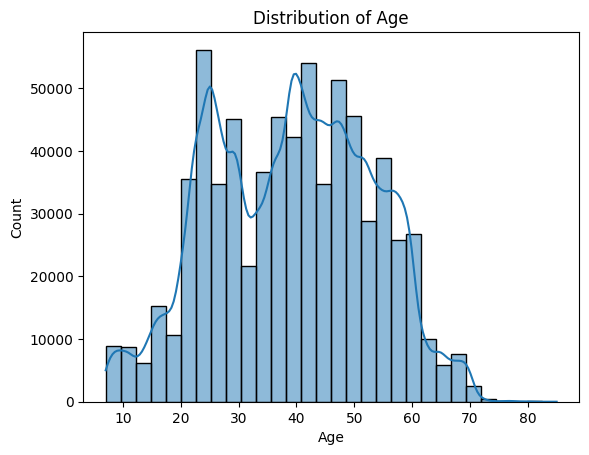

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=train, x="Age", bins=30, kde=True)

plt.title("Distribution of Age")
plt.show()

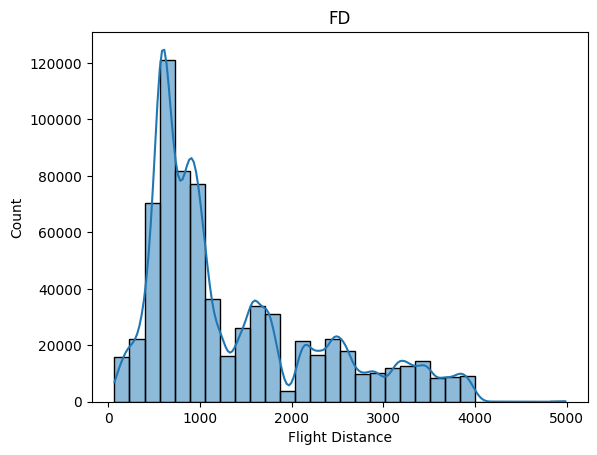

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=train, x="Flight Distance", bins=30, kde=True)

plt.title("FD")
plt.show()

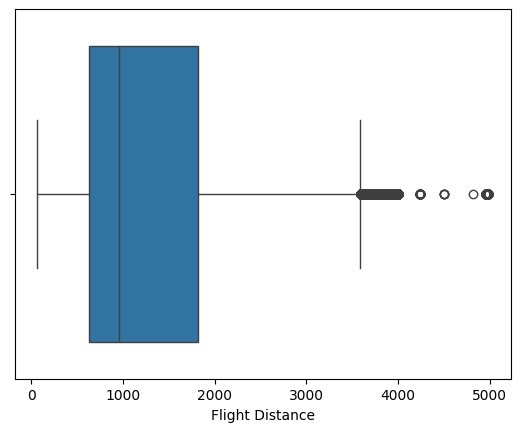

In [14]:
sns.boxplot(data=train, x="Flight Distance")

plt.show()

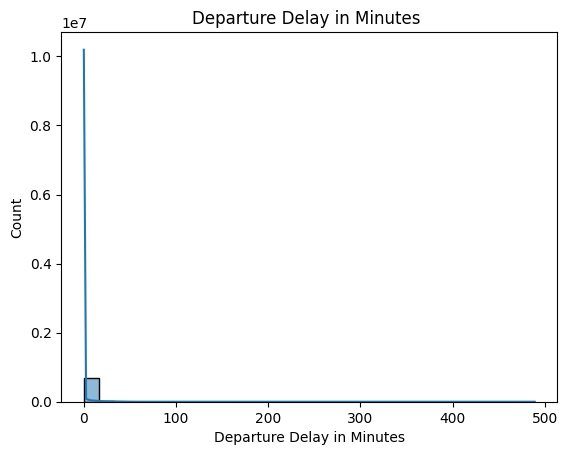

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=train, x="Departure Delay in Minutes", bins=30, kde=True)

plt.title("Departure Delay in Minutes ")
plt.show()

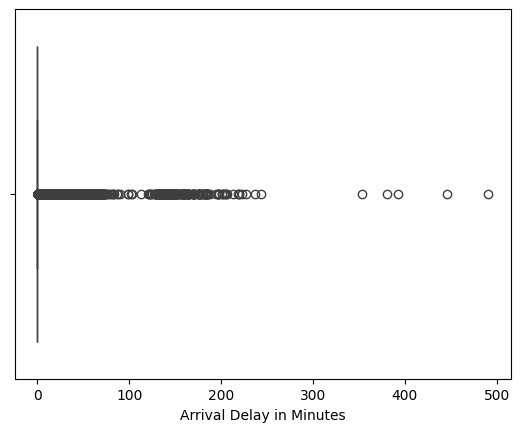

In [16]:
sns.boxplot(data=train, x="Arrival Delay in Minutes")

plt.show()

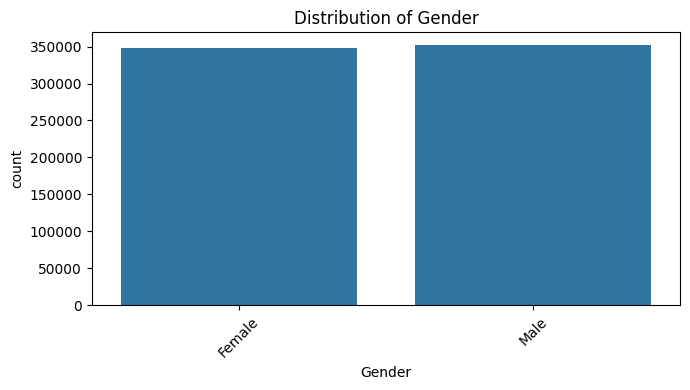

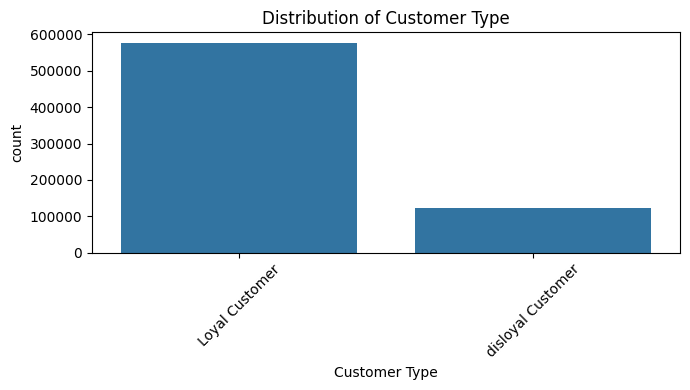

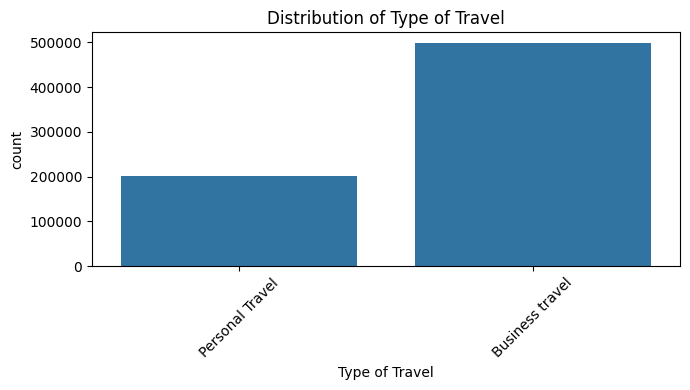

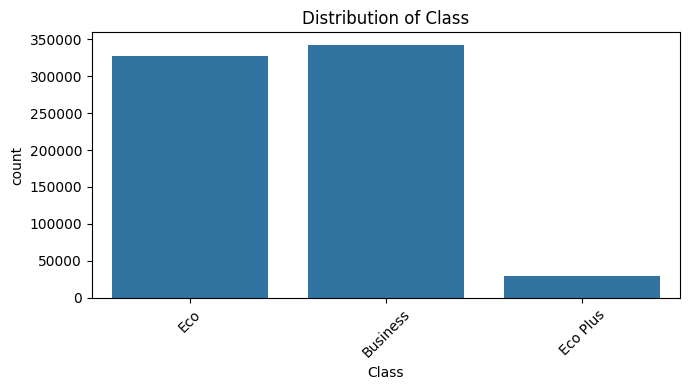

In [17]:
cat_cols = train.select_dtypes(
    include=["object", "category"]
).columns

for col in cat_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=train, x=col)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

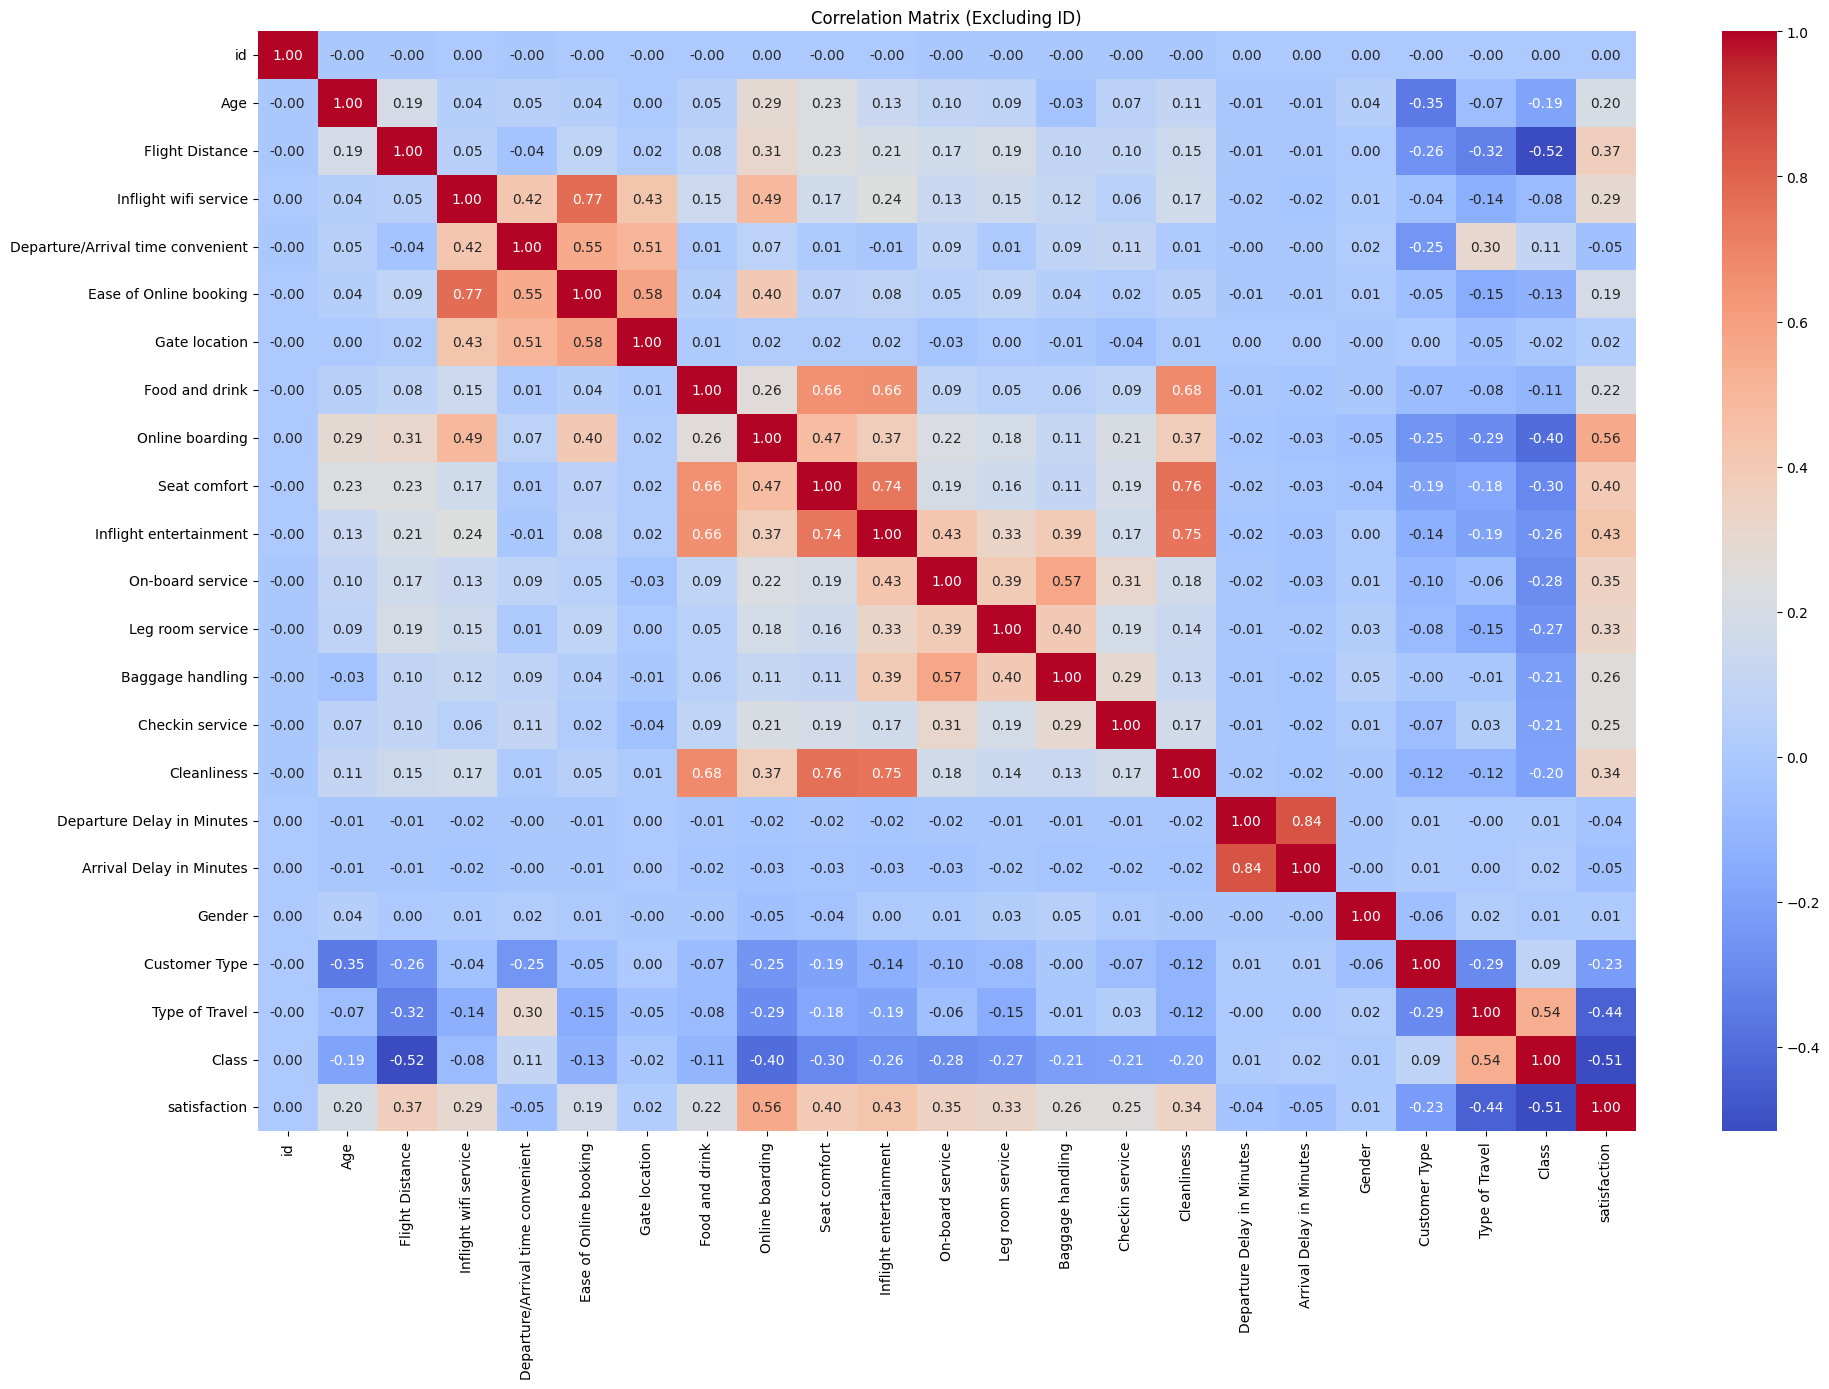

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude ID
df_corr = train.drop(columns=["ID"], errors="ignore")

# Convert categorical columns to numeric codes for correlation
df_corr = df_corr.copy()

for col in df_corr.select_dtypes(include=["object", "category"]).columns:
    df_corr[col] = df_corr[col].astype("category").cat.codes

# Correlation matrix
corr_matrix = df_corr.corr()

# Plot heatmap
plt.figure(figsize=(20, 14))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix (Excluding ID)")
plt.tight_layout()
plt.show()

The colums worth using are Age, Flight Distance, Inflight wifi service, Ease of Online booking, food and drink, Online boarding, Seat Comfort, Inflight entertainment, On-board service, Leg room service, Baggage handling, Checkin service, Cleanliness, Customer Type, Type of Travel, Class.

In [19]:
import pandas as pd

age_bins = [0, 18, 30, 45, 60, 100]
age_labels = [
    "0-18", "19-30", "31-45", "46-60", "61+"
]

train["Age_Group"] = pd.cut(
    train["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

train["Age_Group"].value_counts().sort_index()

Age_Group
0-18      44581
19-30    176701
31-45    234603
46-60    213000
61+       30750
Name: count, dtype: int64

In [20]:
import pandas as pd

age_bins = [0, 18, 30, 45, 60, 100]
age_labels = [
    "0-18", "19-30", "31-45", "46-60", "61+"
]

test["Age_Group"] = pd.cut(
    test["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

test["Age_Group"].value_counts().sort_index()

Age_Group
0-18      19091
19-30     75613
31-45    100830
46-60     91303
61+       13007
Name: count, dtype: int64

In [21]:
train["Flight_Distance_Bin"] = pd.qcut(
    train["Flight Distance"],
    q=5,
    labels=["Very Short", "Short", "Medium", "Long", "Very Long"],
    duplicates="drop"
)
train["Flight_Distance_Bin"].value_counts().sort_index()

Flight_Distance_Bin
Very Short    141090
Short         138813
Medium        140051
Long          139817
Very Long     139864
Name: count, dtype: int64

In [22]:
test["Flight_Distance_Bin"] = pd.qcut(
    test["Flight Distance"],
    q=5,
    labels=["Very Short", "Short", "Medium", "Long", "Very Long"],
    duplicates="drop"
)
test["Flight_Distance_Bin"].value_counts().sort_index()

Flight_Distance_Bin
Very Short    60383
Short         59875
Medium        59795
Long          59826
Very Long     59965
Name: count, dtype: int64

In [23]:
# Ordinal rating columns: keep their numeric order
ordinal_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

# Categorical columns, including your bins
cat_cols = [
    "Age_Group",
    "Flight_Distance_Bin",
    "Customer Type",
    "Type of Travel",
    "Class"
]

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Combine all selected features
selected_cols = ordinal_cols + cat_cols

X = train[selected_cols].copy()
y = train["satisfaction"]

# Preprocess categorical features separately
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         cat_cols),
        ("ordinal", StandardScaler(), ordinal_cols)
    ]
)

# Build the complete pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

y_val_proba = model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_val_proba))

Validation ROC-AUC: 0.919698373050982


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

# Rating features: keep numeric
ordinal_cols = [
    'Inflight wifi service',
    'Ease of Online booking',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Cleanliness'
]

# Categorical features
cat_cols = [
    'Customer Type',
    'Type of Travel',
    'Class',
    'Age_Group',
    'Flight_Distance_Bin'
]

features = ordinal_cols + cat_cols

X = train[features].copy()
y = train['satisfaction'].copy()

# Tell CatBoost which columns are categorical
for col in cat_cols:
    X[col] = X[col].astype(object).fillna('Unknown').astype(str)
# Split the data
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=100,
    random_seed=42
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_cols,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100
)

# Evaluate using prediction probabilities
y_val_proba = model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba))

0:	test: 0.9344124	best: 0.9344124 (0)	total: 463ms	remaining: 7m 42s
100:	test: 0.9532720	best: 0.9532720 (100)	total: 34s	remaining: 5m 2s
200:	test: 0.9547384	best: 0.9547384 (200)	total: 1m 6s	remaining: 4m 24s
300:	test: 0.9552458	best: 0.9552458 (300)	total: 1m 37s	remaining: 3m 47s
400:	test: 0.9554701	best: 0.9554701 (400)	total: 2m 7s	remaining: 3m 11s
500:	test: 0.9555940	best: 0.9555963 (487)	total: 2m 38s	remaining: 2m 37s
600:	test: 0.9556799	best: 0.9556815 (597)	total: 3m 8s	remaining: 2m 5s
700:	test: 0.9557232	best: 0.9557232 (698)	total: 3m 39s	remaining: 1m 33s
800:	test: 0.9557729	best: 0.9557729 (800)	total: 4m 9s	remaining: 1m 2s
900:	test: 0.9558061	best: 0.9558061 (900)	total: 4m 40s	remaining: 30.9s
999:	test: 0.9558516	best: 0.9558534 (998)	total: 5m 11s	remaining: 0us

bestTest = 0.955853419
bestIteration = 998

Shrink model to first 999 iterations.
Validation ROC-AUC: 0.955853418998573


In [28]:
from sklearn.model_selection import train_test_split

train_idx, val_idx = train_test_split(
    train.index,
    test_size=0.2,
    random_state=42,
    stratify=train['satisfaction']
)

In [29]:
# Use original numerical features, not the bins
features_unbinned = [
    *ordinal_cols,
    *cat_cols,
    'Age',
    'Flight Distance'
]

X = train[features_unbinned].copy()
y = train['satisfaction'].copy()

# Keep categorical columns compatible with CatBoost
for col in cat_cols:
    X[col] = (
        X[col].astype(object)
        .fillna('Unknown')
        .astype(str)
    )

# Use the SAME validation split as your binned experiment
X_train = X.loc[train_idx].copy()
X_val = X.loc[val_idx].copy()
y_train = y.loc[train_idx]
y_val = y.loc[val_idx]

model_unbinned = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=100
)

model_unbinned.fit(
    X_train,
    y_train,
    cat_features=cat_cols,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    verbose=100
)

# Evaluate
y_proba_unbinned = model_unbinned.predict_proba(X_val)[:, 1]

auc_unbinned = roc_auc_score(y_val, y_proba_unbinned)

print("Unbinned CatBoost ROC-AUC:", auc_unbinned)

0:	test: 0.9337921	best: 0.9337921 (0)	total: 400ms	remaining: 6m 40s
100:	test: 0.9532959	best: 0.9532959 (100)	total: 34.1s	remaining: 5m 3s
200:	test: 0.9550617	best: 0.9550617 (200)	total: 1m 7s	remaining: 4m 28s
300:	test: 0.9556455	best: 0.9556455 (300)	total: 1m 41s	remaining: 3m 55s
400:	test: 0.9559754	best: 0.9559754 (400)	total: 2m 14s	remaining: 3m 20s
500:	test: 0.9562016	best: 0.9562022 (499)	total: 2m 46s	remaining: 2m 46s
600:	test: 0.9563639	best: 0.9563639 (600)	total: 3m 20s	remaining: 2m 13s
700:	test: 0.9565209	best: 0.9565209 (700)	total: 3m 53s	remaining: 1m 39s
800:	test: 0.9566066	best: 0.9566087 (799)	total: 4m 27s	remaining: 1m 6s
900:	test: 0.9566997	best: 0.9566997 (900)	total: 5m 1s	remaining: 33.1s
999:	test: 0.9567722	best: 0.9567722 (999)	total: 5m 34s	remaining: 0us

bestTest = 0.9567722067
bestIteration = 999

Unbinned CatBoost ROC-AUC: 0.9567722066539275


In [30]:
y_proba_unbinned = model_unbinned.predict_proba(X_val)[:, 1]

auc_unbinned = roc_auc_score(y_val, y_proba_unbinned)
print("Unbinned ROC-AUC:", auc_unbinned)

Unbinned ROC-AUC: 0.9567722066539275


In [31]:
from catboost import CatBoostClassifier
import pandas as pd

# Features and target
features = [
    *ordinal_cols,
    *cat_cols,
    'Age',
    'Flight Distance'
]

X = train[features].copy()
y = train['satisfaction'].copy()

X_test = test[features].copy()

# Handle categorical columns consistently
for col in cat_cols:
    X[col] = X[col].astype(object).fillna('Unknown').astype(str)
    X_test[col] = X_test[col].astype(object).fillna('Unknown').astype(str)

# Train final candidate model
final_model = CatBoostClassifier(
    iterations=1124,
    depth=8,
    learning_rate=0.08,
    l2_leaf_reg=9,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=100
)

final_model.fit(
    X,
    y,
    cat_features=cat_cols
)

0:	total: 561ms	remaining: 10m 30s
100:	total: 52.9s	remaining: 8m 55s
200:	total: 1m 42s	remaining: 7m 50s
300:	total: 2m 29s	remaining: 6m 47s
400:	total: 3m 15s	remaining: 5m 52s
500:	total: 4m 3s	remaining: 5m 2s
600:	total: 4m 49s	remaining: 4m 12s
700:	total: 5m 37s	remaining: 3m 23s
800:	total: 6m 25s	remaining: 2m 35s
900:	total: 7m 12s	remaining: 1m 46s
1000:	total: 7m 59s	remaining: 58.9s
1100:	total: 8m 46s	remaining: 11s
1123:	total: 8m 57s	remaining: 0us


CatBoostClassifier(depth=8, eval_metric='AUC', iterations=1124, l2_leaf_reg=9, learning_rate=0.08, loss_function='Logloss', random_seed=42, verbose=100)

In [32]:
sample_submission = pd.read_csv(
    '/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv'
)
# Predict probabilities for the positive class
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Fill the sample submission with probabilities
submission = sample_submission.copy()
submission['satisfaction'] = test_probabilities

# Save the file
submission.to_csv('/kaggle/working/submission.csv', index=False)

# Verify
print(submission.head())
print("Submission shape:", submission.shape)
print("Missing values:", submission.isnull().sum().sum())

       id  satisfaction
0  699635      0.217034
1  699636      0.871983
2  699637      0.893164
3  699638      0.091879
4  699639      0.057903
Submission shape: (299844, 2)
Missing values: 0
